In [1]:
from astropy.io import fits

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from scipy import stats as ss
from scipy.io import readsav
from sklearn.decomposition import PCA

from tqdm import tqdm

import tools as t

## Load data

In [2]:
# load files
path_data = '../data/sim_series/'  # directory where the files are saved
N_files = 20  # 20 temporal series (from 0 to 19)
data_spectra = []
data_rv = []
for i in range(N_files):  # files have the same name, only number changes
    data_spectra.append(fits.getdata(path_data + f'flux_norm_6173_lionel_tau1_spatialscaling1_sansrotation_serie{i}.fits'))
    data_rv.append(readsav(path_data + f'res_rv_bis_6173_lionel_tau1_scaling1_sansrot_serie{i}.sav'))
data_spectra = np.array(data_spectra)
data_rv = np.array(data_rv)
print(data_rv[0].keys())

dict_keys(['rv_gauss', 'rv_correl', 'rv_deriv', 'xbiss', 'ybiss', 'l_true', 'lambd', 'flux_moy'])


In [3]:
c = 3e8  # speed of light [m/s]
# extract data
wl = np.array(data_rv[0]['lambd'])  # same wavelength grid for all time series (verified)
times = np.arange(0, len(data_spectra[0]) * 144, 144) / 60 / 24  # time in days, same for all time series
times_sec = times * 86400  # time in sec
# extract RV data
wl = np.array(wl)

## Work with only one TS

In [74]:
# selecting TS
ts_index = 0

spectra_ex = data_spectra[ts_index]

# splitting TS in two halves
N = len(times)
N_half = N // 2

times_half = times[:N_half]

spectra_0 = spectra_ex[:N_half]
spectra_1 = spectra_ex[N_half:]

## Preprocessing (DO ONLY FOR spectra_0 and spectra_1)

In [9]:
# calculate the mean spectra
mean_spec_0 = np.mean(spectra_0, axis=0)
mean_spec_1 = np.mean(spectra_1, axis=0)

d_S0 = np.gradient(mean_spec_0, wl)
d_S1 = np.gradient(mean_spec_1, wl)

In [10]:
Sf_0, D_0 = t.subtract_D(wl, spectra_0, c=c)  # S_f and Doppler vector
Sf_1, D_1 = t.subtract_D(wl, spectra_1, c=c)

spectra_centered_0 = t.double_centering(Sf_0)
spectra_centered_1 = t.double_centering(Sf_1)

## Calculate RV by template matching

In [12]:
# calculate radial velocity by template matching
C_0 = 1000  # continuum constant

# list of RVs for each timestep
rv_0 = np.array([
    t.calculate_rv(wl, mean_spec_0, spectra_0[i], C_0) for i in range(N_half)
    ])

rv_1 = np.array([
    t.calculate_rv(wl, mean_spec_1, spectra_1[i], C_0) for i in range(N_half)
    ])

## PCA

In [17]:
# apply PCA to the centered matrix
n_components = 16

# first half
pca_flux_0 = PCA(n_components=n_components)           # create PCA object
pcs_0 = pca_flux_0.fit_transform(spectra_centered_0)  # fit the model with spectra_centered and apply the dimensionality reduction
loadings_0 = pca_flux_0.components_                   # save loadings
scores_0 = pcs_0.T                                    # save scores
var_0 = pca_flux_0.explained_variance_ratio_          # save PC variation

# second half
pca_flux_1 = PCA(n_components=n_components)           # create PCA object
pcs_1 = pca_flux_1.fit_transform(spectra_centered_1)  # fit the model with spectra_centered and apply the dimensionality reduction
loadings_1 = pca_flux_1.components_                   # save loadings
scores_1 = pcs_1.T                                    # save scores
var_1 = pca_flux_1.explained_variance_ratio_          # save PC variation

In [133]:
print(f'Centred TS of spectra shape: {spectra_centered_0.shape}')
print(f'Loadings shape: {loadings_0.shape}')
print(f'Scores shape: {scores_0.shape}')

Centred TS of spectra shape: (1843, 122)
Loadings shape: (16, 122)
Scores shape: (16, 1843)


In [41]:
# checking if the projection of spectra_centered over the loadings is equal to the scores
proj_0 = np.dot(loadings_0, spectra_centered_0.T) / np.linalg.norm(loadings_0)**2
print(f'Projection shape: {proj_0.shape}')

print((proj_0 == scores_0).all())

Projection shape: (16, 1843)
False


In [134]:
max(times_half)

np.float64(184.20000000000002)

In [54]:
# checking if the projection of spectra_centered over the loadings is equal to the scores

proj_0 = []
for i in range(n_components):
    proj_i = []
    loadings_i = loadings_0[i]
    for j in range(N_half):
        proj_ij = np.dot(loadings_i.T, spectra_centered_0[j]) / np.linalg.norm(loadings_i)**2
        proj_i.append(proj_ij)
    proj_0.append(proj_i)
proj_0 = np.array(proj_0)

In [68]:
(np.round(scores_0, 15) == np.round(proj_0, 15)).all()

np.True_

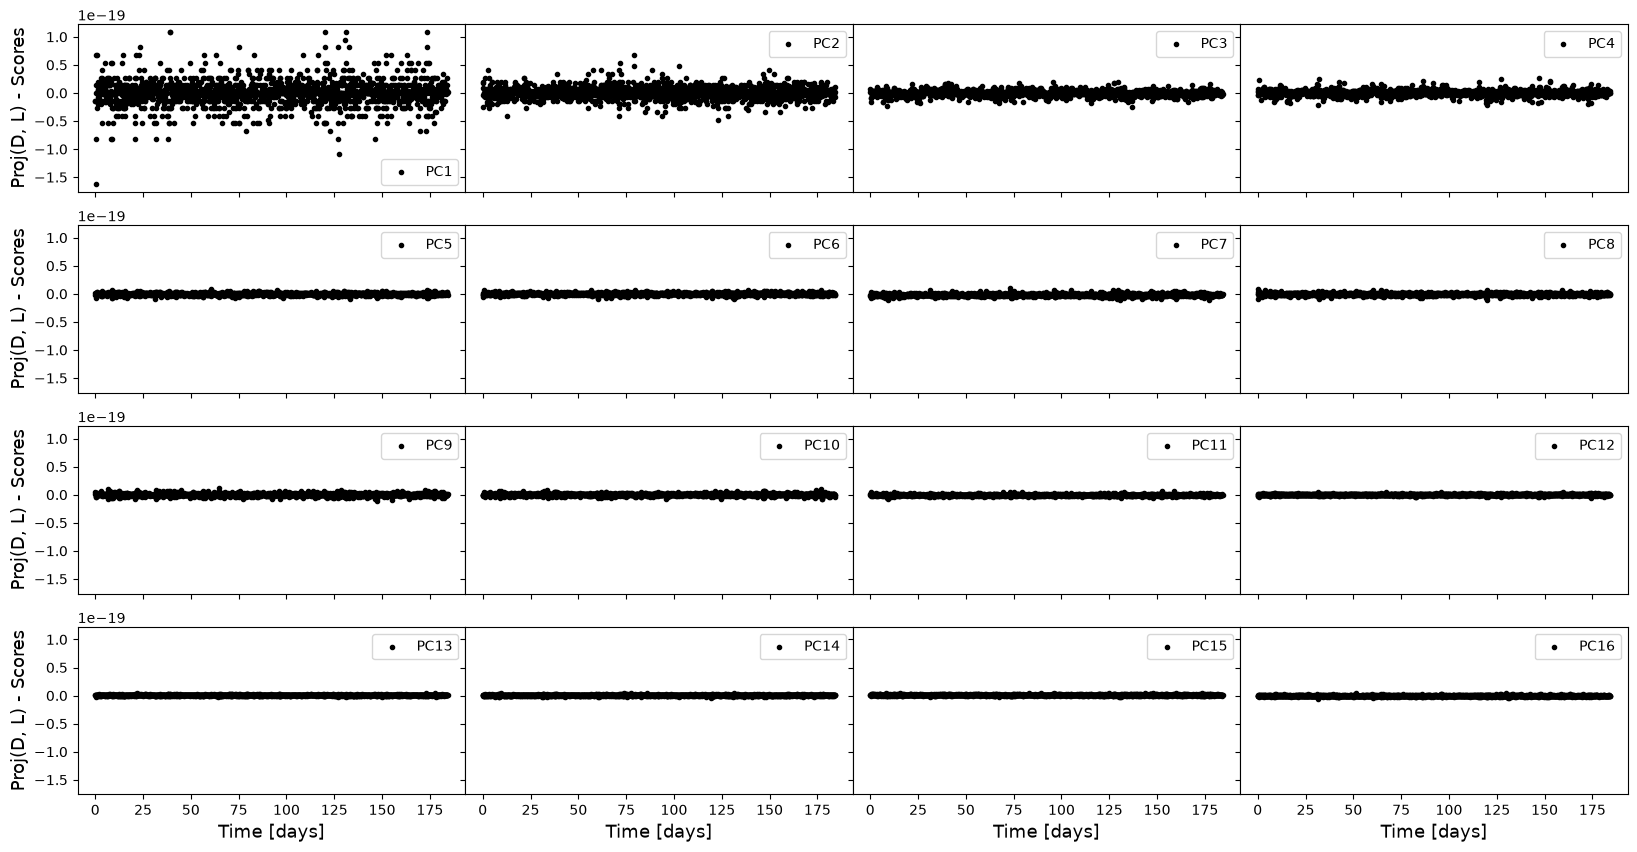

In [85]:
# plot difference between scores and projections for each PC
rows = 4
cols = 4
fig, axs = plt.subplots(rows, cols, figsize=(20, 10), sharex=True, sharey=True)

pc = 0  # PC counter
for row in range(rows):
    for col in range(cols):
        axs[row][col].scatter(times_half, proj_0[pc] - scores_0[pc], color='k', marker='.', label=f'PC{pc + 1}')
        if row == rows - 1:
            axs[row][col].set_xlabel('Time [days]', size=13)
        if col == 0:
            axs[row][col].set_ylabel('Proj(D, L) - Scores', size=13)
        axs[row][col].legend()
        pc += 1

plt.subplots_adjust(wspace=0)
plt.show()

In [106]:
# smallest score values vs maximum difference
for i in range(len(scores_0)):
    print(f'PC {i+1}: Minimum score: {min(np.abs(scores_0[i])):.2e}; Maximum difference: {max(proj_0[i] - scores_0[i]):.2e}.')

PC 1: Minimum score: 8.39e-08; Maximum difference: 1.08e-19.
PC 2: Minimum score: 9.16e-09; Maximum difference: 6.78e-20.
PC 3: Minimum score: 2.37e-09; Maximum difference: 2.03e-20.
PC 4: Minimum score: 8.59e-10; Maximum difference: 2.71e-20.
PC 5: Minimum score: 1.58e-10; Maximum difference: 8.68e-21.
PC 6: Minimum score: 4.46e-10; Maximum difference: 6.56e-21.
PC 7: Minimum score: 8.11e-11; Maximum difference: 1.12e-20.
PC 8: Minimum score: 2.55e-11; Maximum difference: 8.84e-21.
PC 9: Minimum score: 1.11e-10; Maximum difference: 1.28e-20.
PC 10: Minimum score: 1.10e-10; Maximum difference: 1.08e-20.
PC 11: Minimum score: 9.68e-11; Maximum difference: 6.58e-21.
PC 12: Minimum score: 1.03e-10; Maximum difference: 5.55e-21.
PC 13: Minimum score: 5.74e-12; Maximum difference: 3.99e-21.
PC 14: Minimum score: 4.93e-12; Maximum difference: 5.08e-21.
PC 15: Minimum score: 8.83e-12; Maximum difference: 5.39e-21.
PC 16: Minimum score: 1.24e-11; Maximum difference: 4.20e-21.


## Linear Model

In [122]:
# train/test split
train_size = int(.7 * N_half)
I_train_0  = scores_0.T[:train_size]  # matrix with scores as columns
rv_true_train_0 = rv_0[:train_size]
times_train = times_half[:train_size]

I_test_0  = scores_0.T[train_size:]  # matrix with scores as columns
rv_true_test_0 = rv_0[train_size:]
times_test = times_half[train_size:]

# training the model
G = np.dot(I_train_0.T, I_train_0)
b = np.dot(I_train_0.T, rv_true_train_0)
alpha = np.linalg.solve(G, b)

In [123]:
alpha

array([ 6.08139687e+03,  1.70360275e+04,  5.98173597e+04, -8.73617867e+04,
       -6.51432185e+04, -4.62158936e+05,  5.95139335e+05,  6.25375051e+05,
        4.13256523e+05,  7.84021856e+05, -1.68273699e+05,  6.17499277e+06,
        6.04575074e+05,  2.67085493e+06, -1.13868412e+07, -3.53568566e+06])

Scores using the whole TS (from linear_testing.ipynb):

```
array([ 6.3795771e+03,  1.6776572e+04,  7.8773547e+04, -7.0820305e+04,
       -7.8339969e+04, -4.8443328e+05,  4.6573222e+05,  6.1937944e+05,
        3.9534394e+05,  4.9364572e+05,  4.6065034e+05,  6.0899435e+06,
        1.5968818e+06,  1.8360150e+06, -1.0490876e+07,  7.1286250e+06,
        2.8292119e+05, -3.1375859e+05,  1.2220842e+06, -9.8916838e+05],
      dtype=float32)
```

In [125]:
# testing on the test sample of the same half
rv_pred_test_0 = np.dot(I_test_0, alpha)
res_test_0 = rv_true_test_0 - rv_pred_test_0
std_res_0 = np.std(res_test_0)

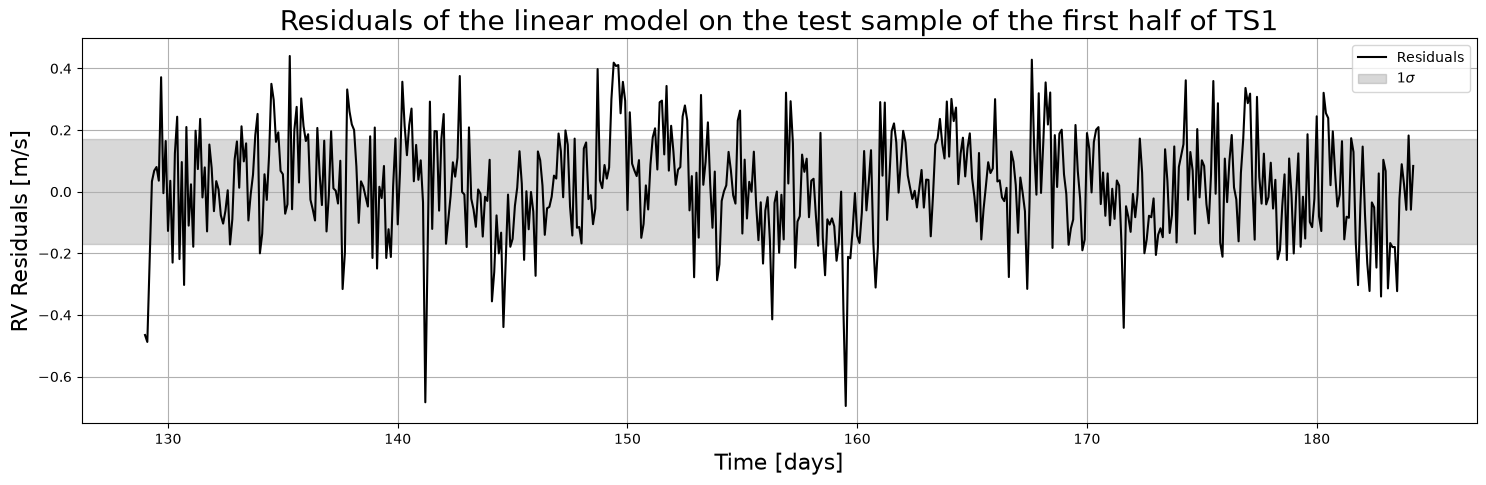

In [127]:
fig, ax = plt.subplots(figsize=(18, 5))
ax.set_title('Residuals of the linear model on the test sample of the first half of TS1', size=20)

ax.grid()
ax.plot(times_test, res_test_0, color='k', label='Residuals')
ax.axhspan(-std_res_0, std_res_0, color='gray', alpha=.3, label=r'$1\sigma$')

ax.set_xlabel('Time [days]', size=16)
ax.set_ylabel('RV Residuals [m/s]', size=16)
ax.legend()

plt.show()

In [129]:
print(f'The standard deviation of the residuals is {std_res_0:.3f} m/s.')

The standard deviation of the residuals is 0.169 m/s.


In [130]:
# testing on the whole second half
I_1 = scores_1.T

rv_pred_1 = np.dot(I_1, alpha)
res_1 = rv_1 - rv_pred_1
std_res_1 = np.std(res_1)

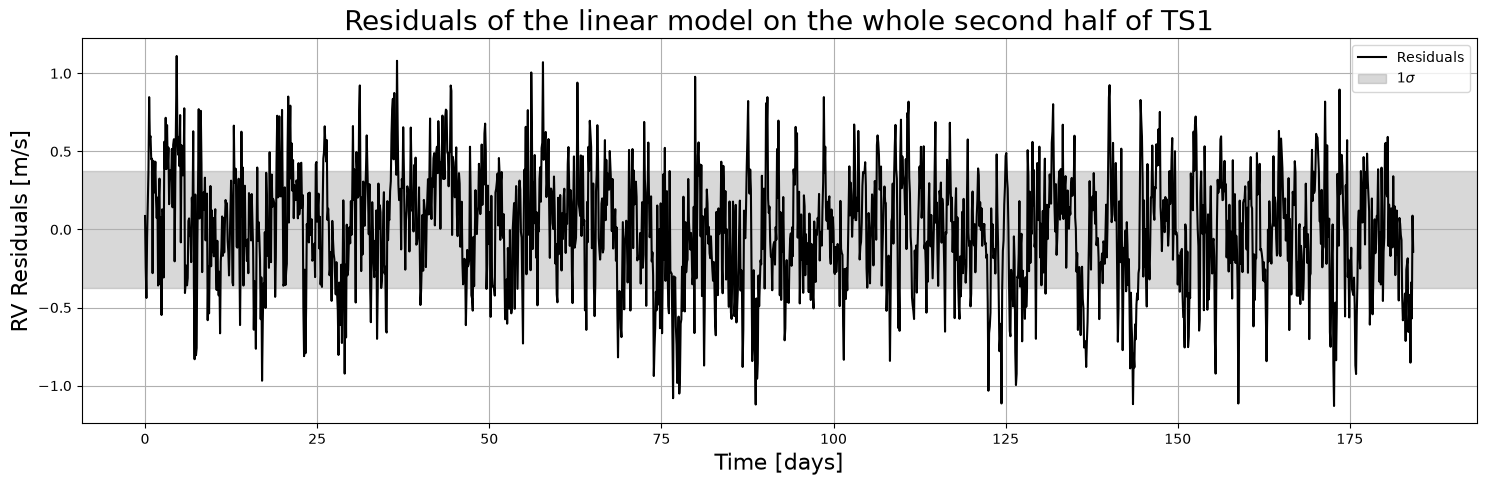

In [131]:
fig, ax = plt.subplots(figsize=(18, 5))
ax.set_title('Residuals of the linear model on the whole second half of TS1', size=20)

ax.grid()
ax.plot(times_half, res_1, color='k', label='Residuals')
ax.axhspan(-std_res_1, std_res_1, color='gray', alpha=.3, label=r'$1\sigma$')

ax.set_xlabel('Time [days]', size=16)
ax.set_ylabel('RV Residuals [m/s]', size=16)
ax.legend()

plt.show()

In [132]:
print(f'The standard deviation of the residuals is {std_res_1:.3f} m/s.')

The standard deviation of the residuals is 0.373 m/s.
